In [1]:
import numpy as np
import matplotlib.pyplot as plt
import os
from tqdm import tqdm
from glob import glob
import pandas as pd
import pickle
import random
from PIL import Image
from glob import glob
import re
#from adjustText import adjust_text
import seaborn as sns
#import statannot
#from statannotations.Annotator import Annotator
import argparse
#import torch
import wandb
import sys
from functools import reduce
import torch
import math
import io
#import colorcet as cc
import scipy
#from adjustText import adjust_text
from sklearn.metrics import roc_auc_score, recall_score
from scipy.stats import ttest_rel


sys.path.append('../../MARS')
import MARS.run_lars.utils
from MARS.run_lars.dataset import get_datasets, dataset_center
from MARS.run_lars.utils import model_prediction, my_model, model_prediction_dual_mipview, my_model_feat_fusion

In [42]:
df_old = pd.read_csv('/gpfs/data/mayerhoeferlab/projects/myeloma/results/run_lars_on_mars_postfiltering/pred_val_0.csv')
df_new = pd.read_csv('/gpfs/data/mayerhoeferlab/projects/myeloma/results/2D_all_seeds_prediction_using_LARS/val/pred_val_0.csv')

df_old['version'] = 'old'
df_new['version'] = 'new'

assert(df_old['fullfile'].equals(df_new['fullfile']))

In [32]:
df_old.columns[:65]

Index(['filepath', 'filename', 'filename_header', 'fullfile', 'patient_age',
       'patient_sex', 'patient_weight', 'smoking_status', 'accession',
       'study_uid', 'series_uid', 'scan_time', 'modality', 'matrix_size_1',
       'matrix_size_2', 'matrix_size_3', 'pixel_size_1', 'pixel_size_2',
       'pixel_size_3', 'pixel_size_3_str', 'slice_thickness',
       'description_series', 'description_study', 'admitting_diagnoses',
       'protocol_name', 'image_comments', 'body_part', 'manufacturer',
       'manufacturer_model', 'software', 'convolution_kernel',
       'factor_bqml2suv', 'xray_tube_current', 'kvp', 'contrast_agent',
       'patient_position', 'imaging_plane', 'image_orientation',
       'patient_history', 'img_max', 'img_min', 'img_mean', 'img_std',
       'img_sum', 'img_count_nonzeros', 'img_mean_nonzeros',
       'img_std_nonzeros', 'img_sum_nonzeros', 'reconstruction', 'corrections',
       'pixel_unit', 'frame_duration', 'tracer', 'tracer_injection_time',
       'tra

In [40]:
merged = df_old.merge(df_new, on='fullfile', suffixes=('_old', '_new'))
merged = merged[['fullfile', 'probs_old', 'probs_new', 'PET_jco_old']]
merged

,fullfile,probs_old,probs_new,PET_jco_old
0,15476574/15476574_pt_0.h5,0.978964,7.529464e-02,1.0
1,15476574/15476574_pt_0.h5,0.978964,5.410756e-01,1.0
2,8749855/8749855_pt_0.h5,0.000170,5.470351e-04,0.0
3,8749855/8749855_pt_0.h5,0.000170,5.684094e-06,0.0
4,25763435/25763435_pt_0.h5,0.000132,5.774314e-07,0.0
...,...,...,...,...
587,40275445/40275445_pt_0.h5,0.188754,1.173957e-01,1.0
588,19394299/19394299_pt_0.h5,0.012985,1.482049e-01,0.0
589,19394299/19394299_pt_0.h5,0.012985,6.271892e-04,0.0
590,17946909/17946909_pt_0.h5,0.000071,1.277078e-05,0.0


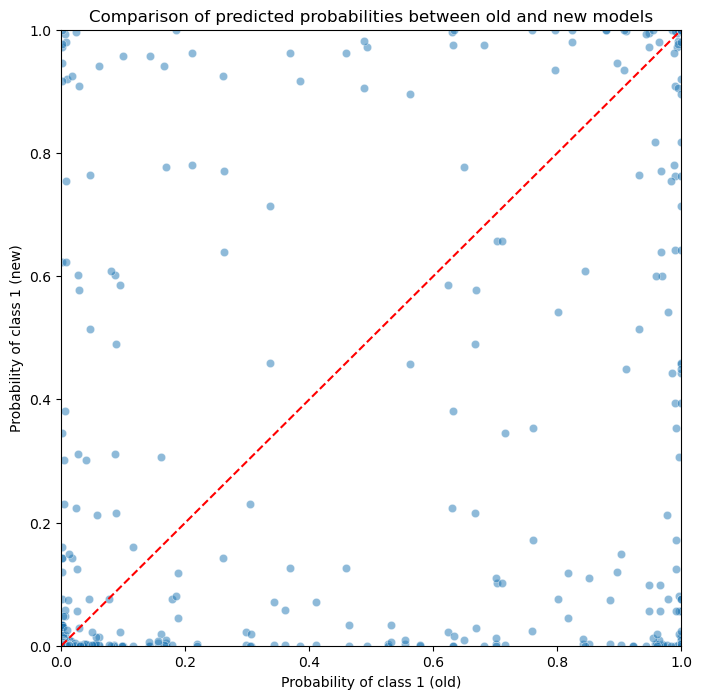

In [37]:
# scatterplot the probs in df_old vs df_new
plt.figure(figsize=(8,8))
sns.scatterplot(x='probs_old', y='probs_new', data=df_old.merge(df_new, on='fullfile', suffixes=('_old', '_new')), alpha=0.5)
plt.plot([0,1], [0,1], 'r--')
plt.xlabel('Probability of class 1 (old)')
plt.ylabel('Probability of class 1 (new)')
plt.title('Comparison of predicted probabilities between old and new models')
plt.xlim(0,1)
plt.ylim(0,1)
plt.show()

In [19]:
df_old.columns[60:]

Index(['PET_imwg', 'mipview', 'probs', 'F1', 'F2', 'F3', 'F4', 'F5', 'F6',
       'F7',
       ...
       'F504', 'F505', 'F506', 'F507', 'F508', 'F509', 'F510', 'F511', 'F512',
       'version'],
      dtype='object', length=516)

In [30]:
dfo

,feature,correlation
328,F395,1.000000
149,F233,1.000000
233,F309,1.000000
60,F153,1.000000
320,F388,1.000000
...,...,...
378,F44,0.999998
492,F81,0.999998
324,F391,0.999998
258,F331,0.999998


In [41]:
# correlation between probs columns
corr = merged[['probs_old', 'probs_new']].corr().iloc[0,1]
print(f'Correlation between probs_old and probs_new: {corr:.4f}')

Correlation between probs_old and probs_new: 0.5796


In [28]:
# visualize how correlated the feature columns are to each other (e.g. F1 in both, F2, in both, etc.)
# we can do this as a strip plot
# where values are pearson correlation
feature_cols_old = sorted([col for col in df_old.columns if col.startswith('F')])
feature_cols_new = sorted([col for col in df_new.columns if col.startswith('F')])
correlations = []
names = []
for col_old, col_new in zip(feature_cols_old, feature_cols_new):
    corr = np.corrcoef(df_old[col_old], df_new[col_new])[0,1]
    correlations.append(corr)
    names.append(col_old)
dfo = pd.DataFrame({'feature': names, 'correlation': correlations}).sort_values('correlation', ascending=False)
plt.figure(figsize=(10,5))



<Figure size 1000x500 with 0 Axes>

<Figure size 1000x500 with 0 Axes>